In [1]:
# 공부시간에 따른 성적을 다항회귀로 예측

In [42]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [43]:
df = pd.read_csv('data/study.csv', sep='\t')
df

,our,score
0,0.5,10
1,1.2,8
2,1.8,14
3,2.4,26
4,2.6,22
5,3.2,30
6,3.9,42
7,4.4,48
8,4.5,38
9,5.0,58


In [44]:
hour = df.iloc[:,:1]
score = df.iloc[:,1:]
score.head()

,score
0,10
1,8
2,14
3,26
4,22


In [45]:
train_data, test_data, train_label, test_label = \
train_test_split(hour,score)

In [46]:
train_poly = np.column_stack((train_data**2, train_data))
test_poly = np.column_stack((test_data**2, test_data))

In [47]:
lr = LinearRegression()
lr.fit(train_poly,train_label)
predict = lr.predict(test_poly)
print(f"예측값:{predict}")
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print("train평가:", score)
print("test평가:", score2)

예측값:[[-3.14414892]
 [15.37982942]
 [57.97007038]
 [49.17141638]
 [65.21376709]]
train평가: 0.9602263232375294
test평가: 0.8698930548126296


In [49]:
indata = input("공부시간을 입력하세요:")
indata = float(indata)

predict = lr.predict([[indata**2,indata]]) 

print("성적예상:", predict)

성적예상: [[83.56939787]]


Text(0, 0.5, '성적')

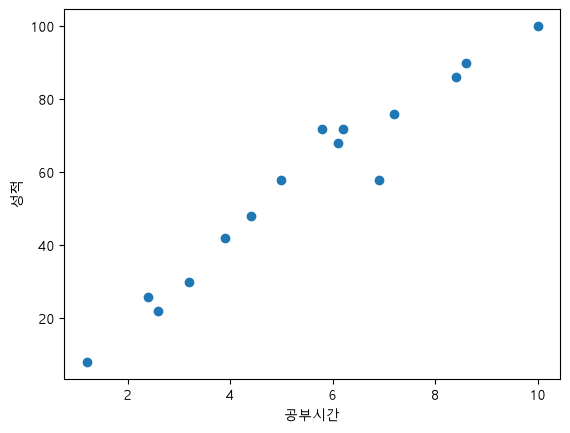

In [50]:
plt.scatter(train_data, train_label)

plt.xlabel('공부시간')
plt.ylabel('성적')